# Notes EA SPORTS FC et valeur marchande

La note FIFA (EA SPORTS FC) et la valeur marchande Transfermarkt sont deux évaluations du même
joueur, faites par des acteurs différents : la première mesure le **niveau actuel** du joueur
dans le jeu, la seconde le **prix** auquel il pourrait être transféré. Elles ne dépendent pas
l'une de l'autre : on cherche ce qu'elles récompensent en commun, et surtout **où et pourquoi
elles divergent**.

**Sommaire**

- Partie A : les notes FIFA
  - [A0. Préparation des données](#A0.-Préparation-des-données)
  - [A1. Distribution des notes](#A1.-Distribution-des-notes)
  - [A2. Note, âge, poste et championnat](#A2.-Note,-âge,-poste-et-championnat)
  - [A3. Note et performances réelles](#A3.-Note-et-performances-réelles)
- Partie B : comparaison avec la valeur marchande
  - [B1. Le lien entre note et valeur](#B1.-Le-lien-entre-note-et-valeur)
  - [B2. Mêmes facteurs, poids différents](#B2.-Mêmes-facteurs,-poids-différents)
  - [B3. Écart entre le marché et FIFA](#B3.-Écart-entre-le-marché-et-FIFA)
  - [B4. Évolution sur quatre saisons](#B4.-Évolution-sur-quatre-saisons)

# Partie A : les notes FIFA

## A0. Préparation des données

On reprend les joueurs de l'analyse des valeurs marchandes (au moins 900 minutes jouées en
2025-26) et on leur associe leur note dans **EA SPORTS FC 27**. Cette édition est sortie en
septembre 2026 : sa note reflète la saison 2025-26, comme la valeur au 30 juin 2026.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from valeur_marchande.transfermarkt import load_snapshot, load_panel
from valeur_marchande.ea_fc import load_matched, add_ratings_to_panel
from valeur_marchande.analyse import (ORDRE_POSTES, FACTEURS, preparer_joueurs,
                                      tableau_coefficients, importance_facteurs)

In [2]:
joueurs = preparer_joueurs(load_snapshot())
notes = load_matched()   # une ligne par joueur et par édition (FIFA 23 à FC 27)

notes["edition"].value_counts()

edition
fc24      6385
fc27      6310
fc26      6118
fifa23    6117
fc25      5793
Name: count, dtype: int64

In [3]:
COLONNES_NOTES = ["player_id", "overall_rating", "pace", "shooting", "passing",
                  "dribbling", "defending", "physical"]
notes_fc27 = notes.loc[notes["edition"] == "fc27", COLONNES_NOTES]
joueurs_notes = joueurs.merge(notes_fc27, on="player_id")
joueurs_notes = joueurs_notes.rename(columns={"overall_rating": "note"})

print(f"{len(joueurs_notes)} joueurs avec une note FC 27, sur {len(joueurs)} "
      f"({len(joueurs_notes) / len(joueurs):.0%})")

2678 joueurs avec une note FC 27, sur 2942 (91%)


Les joueurs sans note sont ceux que le rapprochement entre Transfermarkt et EA n'a pas
retrouvés (nom ou date de naissance trop différents, joueur absent du jeu). Sont-ils différents
des autres ?

In [4]:
joueurs["a_une_note"] = joueurs["player_id"].isin(notes_fc27["player_id"])
joueurs.groupby("a_une_note")[["valeur_millions", "age", "minutes_2025_26"]].median()

,valeur_millions,age,minutes_2025_26
a_une_note,,,
False,0.9,29.0,1527.0
True,6.0,26.0,2169.5


91 % des joueurs de l'analyse (2 678 sur 2 942) ont une note FC 27. Les joueurs sans note sont vraiment moins valorisés (valeur médiane de 0,9 M€ contre 6,0 M€), un peu plus âgés (29 ans contre 26) et jouent moins (1 527 minutes contre 2 170). Il s'agit surtout de joueurs moins connus, ou absents du jeu. L'échantillon étudié est donc orienté vers les bons joueurs : c'est une limite à garder en tête, les résultats suivants portent surtout sur les joueurs les mieux valorisés.

## A1. Distribution des notes

In [5]:
joueurs_notes["note"].describe().round(1)

count    2678.0
mean       74.7
std         5.2
min        55.0
25%        71.0
50%        75.0
75%        78.0
max        91.0
Name: note, dtype: float64

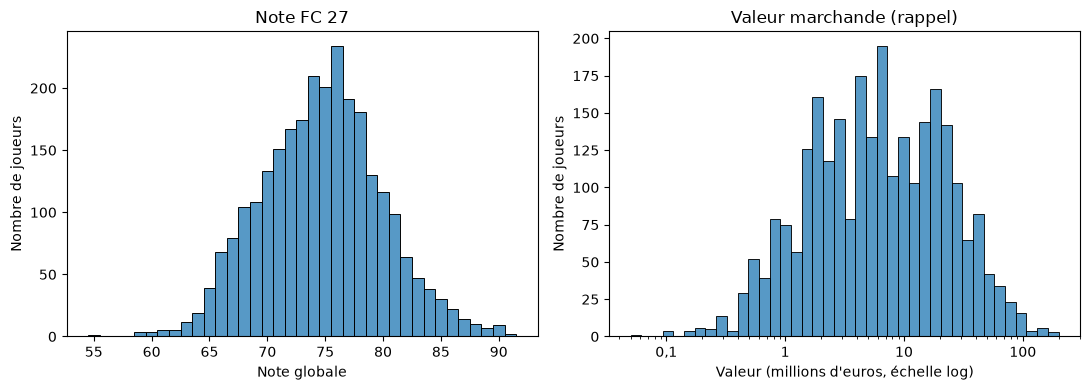

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(data=joueurs_notes, x="note", discrete=True, ax=axes[0])
axes[0].set(title="Note FC 27", xlabel="Note globale", ylabel="Nombre de joueurs")

sns.histplot(data=joueurs_notes, x="valeur_millions", bins=40, log_scale=True, ax=axes[1])
axes[1].set_xticks([0.1, 1, 10, 100], labels=["0,1", "1", "10", "100"])
axes[1].set(title="Valeur marchande (rappel)", xlabel="Valeur (millions d'euros, échelle log)",
            ylabel="Nombre de joueurs")

plt.tight_layout()
plt.show()

La note moyenne bouge-t-elle d'une édition à l'autre ? (tous les joueurs appariés)

In [7]:
ORDRE_EDITIONS = ["fifa23", "fc24", "fc25", "fc26", "fc27"]
(
    notes
    .groupby("edition")["overall_rating"]
    .agg(["count", "mean", "median"])
    .loc[ORDRE_EDITIONS]
    .round(1)
)

,count,mean,median
edition,,,
fifa23,6117,69.9,70.0
fc24,6385,69.8,70.0
fc25,5793,70.7,71.0
fc26,6118,70.6,70.0
fc27,6310,70.6,70.0


La note FC 27 des 2 678 joueurs est resserrée et à peu près symétrique : la moyenne est de 74,7 (et médiane 75, écart-type 5,2), et la moitié des joueurs ont une note entre 71 et 78, pour des notes allant de 55 à 91. La valeur marchande, au contraire, s'étale sur plusieurs puissances de 10. La note est donc une échelle fermée qui distingue relativement peu les meilleurs joueurs : quelques points d'écart au sommet de l'échelle peuvent correspondre à une valeur deux ou trois fois plus élevée. L'échelle est stable d'une édition à l'autre : sur l'ensemble des joueurs appariés, la note moyenne reste autour de 70 de FIFA 23 à FC 27, ce qui permet de comparer les éditions. Notre échantillon a une moyenne plus haute (74,7) car on ne garde que les joueurs ayant joué au moins 900 minutes dans les grands championnats, qui sont en moyenne meilleurs.

## A2. Note, âge, poste et championnat

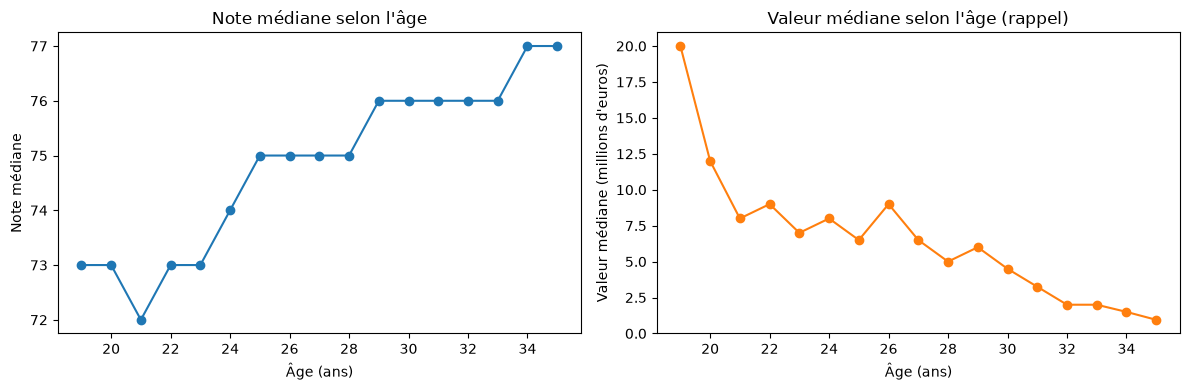

In [8]:
effectifs_age = joueurs_notes["age"].value_counts()
ages_retenus = effectifs_age[effectifs_age >= 20].index
par_age = (
    joueurs_notes
    .loc[joueurs_notes["age"].isin(ages_retenus)]
    .groupby("age")[["note", "valeur_millions"]]
    .median()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(par_age.index, par_age["note"], marker="o")
axes[0].set(title="Note médiane selon l'âge", xlabel="Âge (ans)", ylabel="Note médiane")
axes[1].plot(par_age.index, par_age["valeur_millions"], marker="o", color="tab:orange")
axes[1].set(title="Valeur médiane selon l'âge (rappel)", xlabel="Âge (ans)",
            ylabel="Valeur médiane (millions d'euros)")
plt.tight_layout()
plt.show()

In [9]:
ordre_championnats = (
    joueurs_notes
    .groupby("championnat")["note"]
    .median()
    .sort_values(ascending=False)
    .index
)
pd.pivot_table(joueurs_notes, values="note", index="championnat", columns="poste",
               aggfunc="median").loc[ordre_championnats, ORDRE_POSTES]

poste,Gardien,Défenseur,Milieu,Attaquant
championnat,,,,
Premier League,79.0,79.0,79.0,78.5
Bundesliga,78.0,75.0,76.0,76.0
Liga,79.0,76.0,76.0,76.0
Serie A,77.0,75.0,75.0,76.0
Ligue 1,78.0,75.0,75.0,76.0
Liga Portugal,72.5,70.0,71.0,72.0
Eredivisie,71.0,70.0,69.0,70.0
Pro League,71.0,70.0,71.0,70.0
Süper Lig,69.5,70.0,69.0,71.0


Selon l'âge, la note et la valeur évoluent en sens inverse. La note médiane augmente légèrement, de 73 à 19 ans à 77 à 35 ans, alors que la valeur médiane s'effondre : environ 20 M€ à 19 ans, 8 M€ à 24 ans et 1 M€ à 35 ans, soit une division par 20. La hausse de la note est en partie un effet de sélection : les joueurs âgés qui jouent encore au moins 900 minutes sont les meilleurs de leur génération. C'est une première grande différence entre les deux évaluations : FIFA note seulement le niveau actuel du joueur, alors que le marché paie aussi son avenir. Le classement des championnats est en revanche presque le même que pour la valeur : la note médiane va d'environ 79 en Premier League à environ 70 en Eredivisie, en Pro League et en Süper Lig, avec la Liga, la Bundesliga, la Serie A et la Ligue 1 entre les deux. Enfin, les gardiens ont des notes égales ou supérieures à celles des joueurs de champ dans presque tous les championnats.

## A3. Note et performances réelles

Les notes FIFA suivent-elles les statistiques réelles ? On calcule les corrélations de
Spearman entre la note globale et les statistiques de la saison, poste par poste.

In [10]:
VARIABLES_REELLES = ["age", "minutes_2025_26", "buts_10_matchs", "passes_10_matchs"]

correlations = {}
for poste in ORDRE_POSTES:
    joueurs_poste = joueurs_notes.loc[joueurs_notes["poste"] == poste]
    correlations[poste] = joueurs_poste[VARIABLES_REELLES].corrwith(joueurs_poste["note"],
                                                                    method="spearman")
pd.DataFrame(correlations).round(2)

,Gardien,Défenseur,Milieu,Attaquant
age,0.22,0.23,0.22,0.19
minutes_2025_26,0.56,0.47,0.52,0.48
buts_10_matchs,-0.04,0.15,0.26,0.37
passes_10_matchs,-0.01,0.13,0.28,0.27


Les notes détaillées (tir, passe…) suivent-elles les statistiques qui leur correspondent ?
On regarde les attaquants : la note de tir et les buts, la note de passe et les passes
décisives.

In [11]:
attaquants = joueurs_notes.loc[joueurs_notes["poste"] == "Attaquant"]
print(f"Attaquants : {len(attaquants)}")
print("Tir et buts :",
      round(attaquants["shooting"].corr(attaquants["buts_10_matchs"], method="spearman"), 2))
print("Passe et passes décisives :",
      round(attaquants["passing"].corr(attaquants["passes_10_matchs"], method="spearman"), 2))

Attaquants : 712
Tir et buts : 0.52
Passe et passes décisives : 0.35


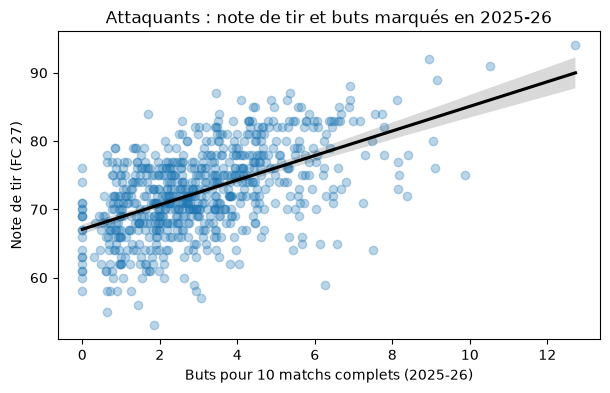

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=attaquants, x="buts_10_matchs", y="shooting", scatter_kws={"alpha": 0.3},
            line_kws={"color": "black"}, ax=ax)
ax.set(title="Attaquants : note de tir et buts marqués en 2025-26",
       xlabel="Buts pour 10 matchs complets (2025-26)", ylabel="Note de tir (FC 27)")
plt.show()

Les notes FIFA suivent en partie les statistiques réelles de la saison. Pour tous les postes, la statistique la plus liée à la note est le temps de jeu (corrélation d'environ 0,5) : les joueurs les mieux notés sont ceux que leurs entraîneurs font le plus jouer. Les buts et les passes décisives comptent surtout pour les attaquants (0,37 et 0,27) et les milieux (0,26 et 0,28), un peu pour les défenseurs, et pas du tout pour les gardiens, ce qui est logique vu leur rôle. On retrouve les mêmes tendances que pour la valeur marchande. Chez les 712 attaquants, les notes détaillées suivent aussi les statistiques correspondantes : la note de tir est liée aux buts marqués (0,52), plus que la note de passe ne l'est aux passes décisives (0,35). Ces liens restent toutefois modérés et le nuage de points est très dispersé : une saison réelle ne se traduit pas mécaniquement en note, car EA tient compte des saisons précédentes et de critères qu'on ne mesure pas ici.

# Partie B : comparaison avec la valeur marchande

## B1. Le lien entre note et valeur

Corrélation de Spearman note / valeur : 0.73


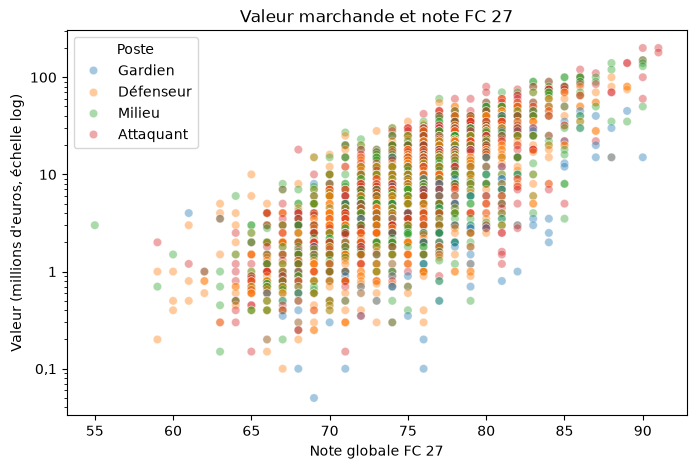

In [13]:
print("Corrélation de Spearman note / valeur :",
      round(joueurs_notes["note"].corr(joueurs_notes["valeur_millions"], method="spearman"), 2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=joueurs_notes, x="note", y="valeur_millions", hue="poste",
                hue_order=ORDRE_POSTES, alpha=0.4, ax=ax)
ax.set_yscale("log")
ax.set_yticks([0.1, 1, 10, 100], labels=["0,1", "1", "10", "100"])
ax.set(title="Valeur marchande et note FC 27", xlabel="Note globale FC 27",
       ylabel="Valeur (millions d'euros, échelle log)")
ax.legend(title="Poste")
plt.show()

En échelle logarithmique, le nuage est à peu près une droite : la valeur est multipliée par
un même facteur à chaque point de note en plus. On mesure ce facteur avec une régression du
log de la valeur sur la note.

In [14]:
modele_note = smf.ols("log_valeur ~ note", data=joueurs_notes).fit()
b_note = modele_note.params["note"]
print(f"Un point de note en plus : valeur multipliée par {np.exp(b_note):.2f} "
      f"(soit {(np.exp(b_note) - 1) * 100:.0f} %)")
print(f"Dix points de plus : valeur multipliée par {np.exp(10 * b_note):.1f}")
print(f"R² = {modele_note.rsquared:.2f}")

Un point de note en plus : valeur multipliée par 1.20 (soit 20 %)
Dix points de plus : valeur multipliée par 6.4
R² = 0.53


La note FIFA et la valeur marchande sont fortement liées : la corrélation de Spearman entre les deux vaut 0,73. En échelle logarithmique, le nuage de points est à peu près une droite. La régression du log de la valeur sur la note montre qu'un point de note en plus correspond en moyenne à une valeur multipliée par 1,20, soit + 20 %, et dix points de plus à une valeur multipliée par 6,4. Les deux évaluations mesurent donc en grande partie la même chose : le niveau du joueur. Mais la note n'explique qu'environ la moitié des écarts de valeur entre joueurs (R² de 0,53). L'autre moitié correspond à ce qui sépare le marché de FIFA, qu'on étudie dans la suite. Sur le graphique, les gardiens se situent plutôt sous le nuage : à note égale, ils valent moins que les joueurs de champ.

## B2. Mêmes facteurs, poids différents

On explique la note avec les mêmes variables que la valeur marchande (âge, poste, championnat,
temps de jeu, buts et passes), puis on compare l'importance de chaque facteur dans les deux cas.

In [15]:
formule = " + ".join(FACTEURS.values())
modele_valeur = smf.ols(f"log_valeur ~ {formule}", data=joueurs_notes).fit()
modele_fifa = smf.ols(f"note ~ {formule}", data=joueurs_notes).fit()
print(f"R² valeur (log) : {modele_valeur.rsquared:.2f}   R² note : {modele_fifa.rsquared:.2f}")

tableau_coefficients(modele_fifa, cible_en_log=False)

R² valeur (log) : 0.71   R² note : 0.67


,coefficient,p_valeur
"C(championnat, Treatment('Ligue 1'))[T.Bundesliga]",-0.420,0.095
"C(championnat, Treatment('Ligue 1'))[T.Eredivisie]",-6.078,0.000
"C(championnat, Treatment('Ligue 1'))[T.Liga]",0.537,0.026
"C(championnat, Treatment('Ligue 1'))[T.Liga Portugal]",-3.821,0.000
"C(championnat, Treatment('Ligue 1'))[T.Premier League]",2.082,0.000
"C(championnat, Treatment('Ligue 1'))[T.Pro League]",-5.863,0.000
"C(championnat, Treatment('Ligue 1'))[T.Serie A]",-0.564,0.020
"C(championnat, Treatment('Ligue 1'))[T.Süper Lig]",-5.115,0.000
"C(poste, Treatment('Défenseur'))[T.Attaquant]",-1.559,0.000
"C(poste, Treatment('Défenseur'))[T.Gardien]",1.581,0.000


In [16]:
importance = (
    importance_facteurs(joueurs_notes, "log_valeur")
    .rename(columns={"r2_perdu_si_retire": "valeur marchande"})
    .merge(importance_facteurs(joueurs_notes, "note")
           .rename(columns={"r2_perdu_si_retire": "note FIFA"}), on="facteur")
)
importance.round(3)

,facteur,valeur marchande,note FIFA
0,Championnat,0.289,0.298
1,Âge,0.211,0.014
2,Poste,0.005,0.013
3,Temps de jeu,0.131,0.160
4,Buts et passes,0.058,0.072


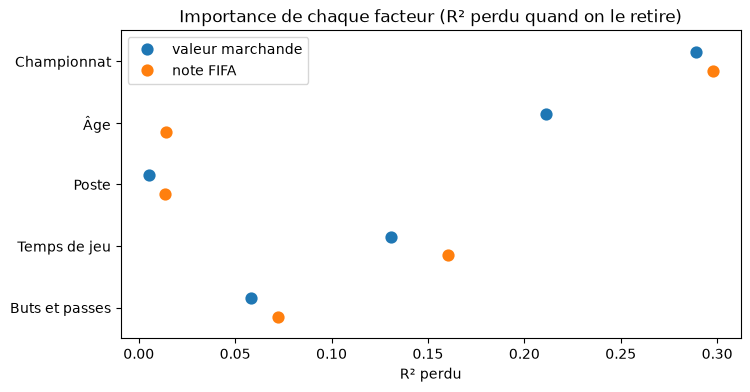

In [17]:
importance_long = importance.melt(id_vars="facteur", var_name="évaluation",
                                  value_name="r2_perdu")

fig, ax = plt.subplots(figsize=(8, 4))
sns.pointplot(data=importance_long, x="r2_perdu", y="facteur", hue="évaluation",
              linestyle="none", dodge=0.3, ax=ax)
ax.set(title="Importance de chaque facteur (R² perdu quand on le retire)",
       xlabel="R² perdu", ylabel="")
ax.legend(title="")
plt.show()

L'effet de l'âge, à tout le reste égal, d'après les deux régressions : écart par rapport
à un joueur de 24 ans, en % de valeur d'un côté et en points de note de l'autre.

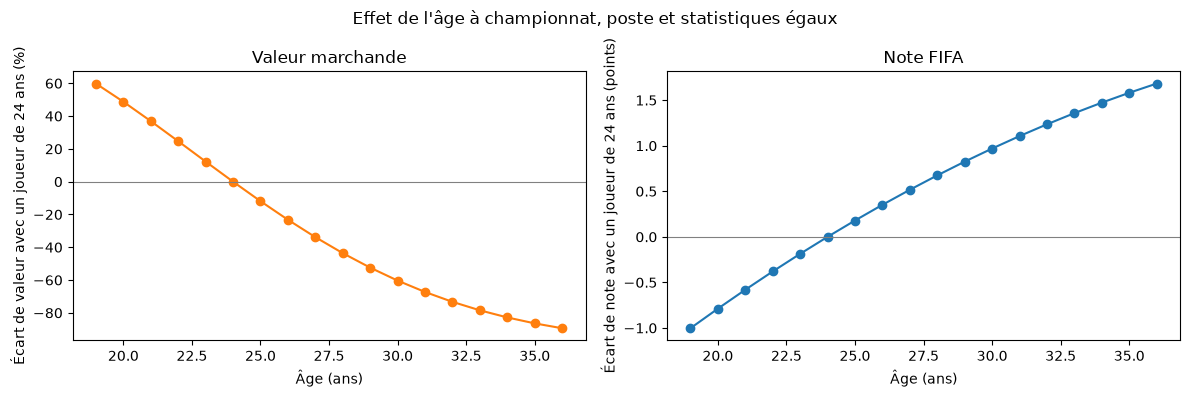

In [18]:
ages = np.arange(19, 37)


def effet_age(modele):
    """Écart (dans l'unité de la variable expliquée) entre chaque âge et 24 ans."""
    b1, b2 = modele.params["age"], modele.params["I(age ** 2)"]
    return b1 * (ages - 24) + b2 * (ages ** 2 - 24 ** 2)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ages, (np.exp(effet_age(modele_valeur)) - 1) * 100, marker="o", color="tab:orange")
axes[0].axhline(0, color="grey", linewidth=0.8)
axes[0].set(title="Valeur marchande", xlabel="Âge (ans)",
            ylabel="Écart de valeur avec un joueur de 24 ans (%)")
axes[1].plot(ages, effet_age(modele_fifa), marker="o")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set(title="Note FIFA", xlabel="Âge (ans)",
            ylabel="Écart de note avec un joueur de 24 ans (points)")
fig.suptitle("Effet de l'âge à championnat, poste et statistiques égaux")
plt.tight_layout()
plt.show()

Les mêmes facteurs (championnat, âge, poste, temps de jeu, buts et passes) expliquent presque aussi bien les deux évaluations : le R² vaut 0,71 pour le log de la valeur et 0,67 pour la note. Mais ils n'ont pas le même poids. Le championnat compte autant pour les deux (environ 0,29-0,30 de R² perdu si on le retire) : FIFA aussi donne de meilleures notes aux joueurs des championnats les plus riches, avec par exemple +2,1 points en Premier League et −6,1 points en Eredivisie par rapport à la Ligue 1, acvec tout le reste égal. Le temps de jeu et les buts et passes comptent un peu plus pour la note que pour la valeur. La grande différence est l'âge : il explique 0,21 du R² de la valeur, mais presque rien pour la note (0,014). Surtout, il joue en sens inverse : à statistiques égales, un joueur de 30 ans vaut environ 60 % de moins qu'un joueur de 24 ans, et 89 % de moins à 36 ans, alors que sa note et légèrement plus élevée (+1 point à 30 ans, +1,7 à 36 ans), probablement parce que FIFA récompense l'expérience et la réputation.

## B3. Écart entre le marché et FIFA

On utilise la régression de B1 (log de la valeur expliqué par la note) : pour chaque joueur, le
**résidu** est l'écart entre sa vraie valeur et la valeur « attendue » pour sa note.
Un résidu positif veut dire que le marché valorise le joueur **plus** que ce que sa note FIFA
laisse attendre ; un résidu négatif, **moins**. On le traduit en pourcentage.

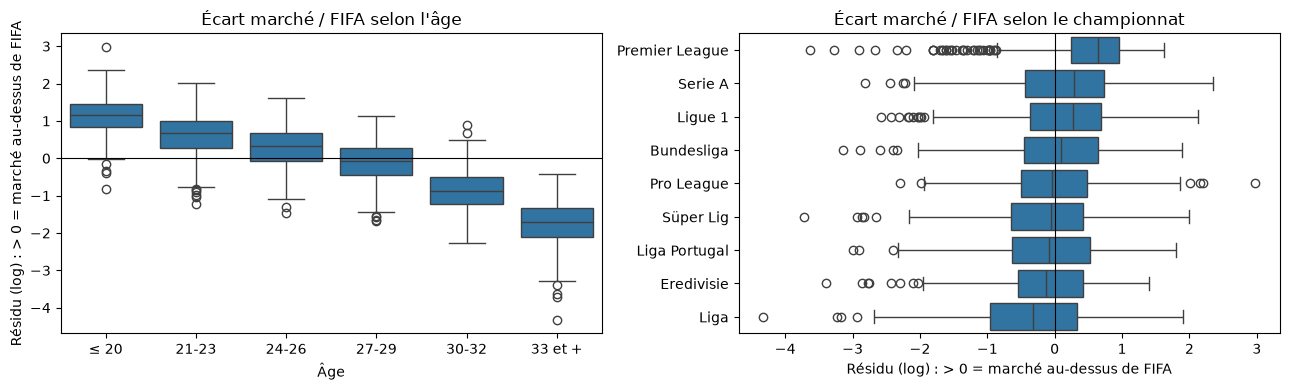

In [19]:
joueurs_notes["residu"] = modele_note.resid
joueurs_notes["ecart_pct"] = (np.exp(joueurs_notes["residu"]) - 1) * 100

joueurs_notes["tranche_age"] = pd.cut(joueurs_notes["age"], bins=[0, 20, 23, 26, 29, 32, 45],
                                      labels=["≤ 20", "21-23", "24-26", "27-29", "30-32",
                                              "33 et +"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=joueurs_notes, x="tranche_age", y="residu", ax=axes[0])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Écart marché / FIFA selon l'âge", xlabel="Âge",
            ylabel="Résidu (log) : > 0 = marché au-dessus de FIFA")

ordre = joueurs_notes.groupby("championnat")["residu"].median().sort_values(ascending=False).index
sns.boxplot(data=joueurs_notes, x="residu", y="championnat",
            order=ordre, ax=axes[1])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(title="Écart marché / FIFA selon le championnat",
            xlabel="Résidu (log) : > 0 = marché au-dessus de FIFA", ylabel="")
plt.tight_layout()
plt.show()

In [20]:
# Écart médian (en %) par tranche d'âge et par poste
pd.pivot_table(joueurs_notes, values="ecart_pct", index="tranche_age", columns="poste",
               aggfunc="median", observed=True).loc[:, ORDRE_POSTES].round(0)

poste,Gardien,Défenseur,Milieu,Attaquant
tranche_age,,,,
≤ 20,128.0,236.0,229.0,203.0
21-23,64.0,83.0,120.0,99.0
24-26,-5.0,34.0,46.0,44.0
27-29,-33.0,-7.0,-12.0,-2.0
30-32,-66.0,-61.0,-56.0,-50.0
33 et +,-84.0,-83.0,-80.0,-81.0


Les joueurs pour qui les deux évaluations divergent le plus :

In [21]:
COLONNES = ["name", "age", "club_name", "note", "valeur_millions", "ecart_pct"]

print("Le marché les valorise beaucoup plus que FIFA :")
display(joueurs_notes.sort_values("ecart_pct", ascending=False)[COLONNES].head(10).round(1))

print("Le marché les valorise beaucoup moins que FIFA :")
display(joueurs_notes.sort_values("ecart_pct")[COLONNES].head(10).round(1))

Le marché les valorise beaucoup plus que FIFA :


,name,age,club_name,note,valeur_millions,ecart_pct
1776,Xander Dierckx,17.0,Royal Antwerp FC,55,3.0,1867.0
633,Jeff Ekhator,19.0,Genoa CFC,68,18.0,954.2
1031,Sascha Britschgi,19.0,Parma Calcio 1913,65,10.0,922.7
376,Nathan De Cat,17.0,RSC Anderlecht,71,27.0,805.6
1538,Lucca Brughmans,18.0,KRC Genk,61,4.0,760.2
392,Tylel Tati,18.0,FC Nantes,71,25.0,738.5
1436,Roggerio Nyakossi,22.0,Oud-Heverlee Leuven,63,5.0,641.5
1282,Renato Nhaga,19.0,Galatasaray,64,6.0,638.9
793,Tiago Gabriel,21.0,US Lecce,69,15.0,629.6
771,Antonio Vergara,23.0,SSC Napoli,69,15.0,629.6


Le marché les valorise beaucoup moins que FIFA :


,name,age,club_name,note,valeur_millions,ecart_pct
2673,Matías Dituro,39.0,Elche CF,76,0.1,-98.7
2677,Paulo Victor,39.0,Alanyaspor,69,0.0,-97.6
2668,Karl Darlow,35.0,Leeds United,76,0.2,-97.4
2675,Remko Pasveer,42.0,Heracles Almelo,71,0.1,-96.6
2591,Idrissa Gueye,36.0,Everton FC,79,0.5,-96.2
2652,Pedro Bigas,36.0,Elche CF,76,0.3,-96.0
2487,Wojciech Szczesny,36.0,FC Barcelona,81,0.8,-95.8
2404,Péter Gulácsi,36.0,RB Leipzig,82,1.0,-95.7
2670,Cassiano,37.0,Casa Pia AC,71,0.2,-95.0
2633,Stefan Savic,35.0,Trabzonspor,76,0.4,-94.7


Qu'est-ce qui explique cet écart ? À **note égale**, on ajoute l'âge, le championnat,
le poste et les statistiques : chaque coefficient dit ce que le marché paie en plus (ou en
moins) de ce que mesure la note.

In [22]:
modele_ecart = smf.ols(f"log_valeur ~ note + {formule}", data=joueurs_notes).fit()
print(f"R² : note seule {modele_note.rsquared:.2f}, note + autres facteurs "
      f"{modele_ecart.rsquared:.2f}")
tableau_coefficients(modele_ecart)

R² : note seule 0.53, note + autres facteurs 0.89


,coefficient,p_valeur,effet_en_pct
"C(championnat, Treatment('Ligue 1'))[T.Bundesliga]",-0.016,0.655,-1.614
"C(championnat, Treatment('Ligue 1'))[T.Eredivisie]",-0.414,0.000,-33.874
"C(championnat, Treatment('Ligue 1'))[T.Liga]",-0.276,0.000,-24.140
"C(championnat, Treatment('Ligue 1'))[T.Liga Portugal]",-0.323,0.000,-27.601
"C(championnat, Treatment('Ligue 1'))[T.Premier League]",0.358,0.000,43.003
"C(championnat, Treatment('Ligue 1'))[T.Pro League]",-0.326,0.000,-27.842
"C(championnat, Treatment('Ligue 1'))[T.Serie A]",0.142,0.000,15.240
"C(championnat, Treatment('Ligue 1'))[T.Süper Lig]",0.079,0.056,8.222
"C(poste, Treatment('Défenseur'))[T.Attaquant]",-0.023,0.455,-2.242
"C(poste, Treatment('Défenseur'))[T.Gardien]",-0.190,0.000,-17.265


In [23]:
# À note égale (et à championnat, poste et statistiques égaux) : écart de valeur avec un
# joueur de 24 ans, en %
ecart_age = pd.Series((np.exp(effet_age(modele_ecart)) - 1) * 100, index=ages)
ecart_age.loc[[19, 21, 24, 27, 30, 33, 36]].round(0)

19    92.0
21    52.0
24     0.0
27   -40.0
30   -67.0
33   -83.0
36   -92.0
dtype: float64

C'est le résultat central de la comparaison. Pour chaque joueur, le résidu de la régression de B1 mesure l'écart entre sa valeur réelle et la valeur attendue pour sa note. Cet écart dépend surtout de l'âge : en écart médian brut, le marché valorise les joueurs de 20 ans ou moins plus de deux fois au-dessus de ce que leur note laisse attendre (environ +200 % à +240 % pour les joueurs de champ), alors que les joueurs de 33 ans et plus valent environ 80 % de moins. Les joueurs les plus sur-valorisés par le marché sont tous des jeunes de 17 à 23 ans, et les plus sous-valorisés des joueurs de 35 ans et plus, souvent des gardiens. Quand on ajoute à la note l'âge, le championnat, le poste et les statistiques, le R² passe de 0,53 à 0,89 : ces facteurs expliquent presque tout l'écart entre le marché et FIFA. À note et autres facteurs égaux, un joueur de 19 ans vaut encore 92 % de plus qu'un joueur de 24 ans, et un joueur de 33 ans 83 % de moins : le marché paie un potentiel et des années de carrière que la note ne mesure pas. Le championnat compte aussi : à note égale, un joueur de Premier League vaut environ 43 % de plus qu'un joueur de Ligue 1, alors qu'un joueur de Liga vaut environ 24 % de moins, sans doute parce que FIFA note les joueurs de Liga plus haut que ce que le marché paie. Enfin, les gardiens valent environ 17 % de moins à note égale, et 1 000 minutes jouées en plus ajoutent environ 12 % de valeur.